# 3. Back-translation data augmentation (RQ4)

Run notebook 1 first

**Pipeline**: Back-translate 800 training questions, keep only the paraphrases that pass a quality check, add them to the training data, retrain DistilBERT with the same settings, and compare with the original model on QQP and PAWS.

In [1]:
# !pip install -q datasets transformers accelerate sentencepiece sacremoses sentence-transformers scikit-learn nltk

In [2]:
import os, re, random
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
import numpy as np
import pandas as pd

SEED = 42
random.seed(SEED)
np.random.seed(SEED)


PROJECT_DIR = r"C:\Users\thiga\OneDrive\Documents\Masters - Big Data\Year 1\Semester 2\COS 802\Project"
OUT = os.path.join(PROJECT_DIR, "results")

if not os.path.isdir(PROJECT_DIR):
    raise FileNotFoundError(f"Project folder not found: {PROJECT_DIR}. Check the path.")

os.makedirs(OUT, exist_ok=True)
print("Saving to:", OUT)

Saving to: C:\Users\thiga\OneDrive\Documents\Masters - Big Data\Year 1\Semester 2\COS 802\Project\results


In [3]:
import matplotlib.pyplot as plt

COLORS = ["seagreen", "dodgerblue", "darkorange"]


def style(ax, grid="y"):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(False)
    ax.tick_params(axis="both", direction="in", length=4, width=0.8)


def save_fig(name):
    plt.tight_layout()
    plt.savefig(f"{OUT}/{name}.png", dpi=300, bbox_inches="tight")

In [4]:
qqp_train = pd.read_csv(f"{OUT}/qqp_train.csv")
qqp_val   = pd.read_csv(f"{OUT}/qqp_val.csv")
qqp_test  = pd.read_csv(f"{OUT}/qqp_test.csv")
paws_test = pd.read_csv(f"{OUT}/paws_test.csv")
print(len(qqp_train), len(qqp_val), len(qqp_test), len(paws_test))

8000 1000 1000 8000


## 1. Generate paraphrases
For 800 randomly chosen training pairs, the first sentence is back-translated. The pair keeps its original label.

In [5]:
import torch
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

N_AUG = 800
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)


def load_seq2seq(name):
    tok = AutoTokenizer.from_pretrained(name)
    model = AutoModelForSeq2SeqLM.from_pretrained(name)
    model = model.to(device)
    model.eval()
    return tok, model


def translate(texts, tok, model, batch_size=32):
    outputs = []

    for i in tqdm(range(0, len(texts), batch_size)):
        batch = texts[i:i + batch_size]
        encoded = tok(batch, return_tensors="pt", padding=True, truncation=True, max_length=128)
        encoded = encoded.to(device)

        with torch.no_grad():
            generated = model.generate(**encoded, max_length=128, num_beams=4)

        decoded = tok.batch_decode(generated, skip_special_tokens=True)
        outputs.extend(decoded)

    return outputs


# Translate
en_de = load_seq2seq("Helsinki-NLP/opus-mt-en-de")
de_en = load_seq2seq("Helsinki-NLP/opus-mt-de-en")

# Select 800 original training pairs and back-translate sentence 1
aug = qqp_train.sample(N_AUG, random_state=SEED).reset_index(drop=True)
german = translate(aug.sentence1.tolist(), *en_de)
aug["bt_sentence1"] = translate(german, *de_en)

display(aug[["sentence1", "bt_sentence1"]].head())

Device: cuda


Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

,sentence1,bt_sentence1
0,Does secondary insurance pay deductibles and c...,Does the secondary insurance pay deductions an...
1,Why are people afraid of darkness?,Why are people afraid of the darkness?
2,I am grumpy nowadays when I wake up. I lose my...,I am grumpy today when I wake up. I lose my te...
3,What is the goal of life?,What is the goal of life?
4,If I touch a contaminated subway handrail (Con...,When I touch a contaminated subway trail (conj...


## Quality filter
A back-translation is accepted only if
* Its sentence embedding **cosine similarity** to the original is at least 0.85.
* Its word overlap with the original is below 0.9.

In [6]:
from sentence_transformers import SentenceTransformer, util
from nltk.metrics.distance import jaccard_distance

# Thresholds for accepting generated paraphrases
MIN_SIM = 0.85
MAX_OVERLAP = 0.90

# Load the sentence embedding model
embedder = SentenceTransformer("all-MiniLM-L6-v2")


def word_overlap(a, b):

    # Extract unique lowercase words
    words_a = set(re.findall(r"\w+", a.lower()))
    words_b = set(re.findall(r"\w+", b.lower()))

    # Jaccard similarity = 1 - Jaccard distance
    return 1 - jaccard_distance(words_a, words_b)


# Calculate semantic similarity

original_emb = embedder.encode(aug["sentence1"].tolist(), convert_to_tensor=True)

backtranslated_emb = embedder.encode(aug["bt_sentence1"].tolist(), convert_to_tensor=True)

# Compare each original sentence with its paraphrase
aug["similarity"] = util.pairwise_cos_sim(original_emb, backtranslated_emb).cpu().numpy()


# Calculate lexical overlap

overlap_scores = []

for original, paraphrase in zip(aug["sentence1"], aug["bt_sentence1"]):
    overlap_scores.append(word_overlap(original, paraphrase))

aug["overlap"] = overlap_scores


# Apply the quality filters

# Accept candidates with high semantic similarity and sufficient wording changes
aug["accepted"] = ((aug["similarity"] >= MIN_SIM) & (aug["overlap"] < MAX_OVERLAP))

aug.to_csv(f"{OUT}/augmented_candidates.csv", index=False)


# Calculate the number and percentage of accepted candidates
accepted_count = aug["accepted"].sum()
acceptance_rate = aug["accepted"].mean()

print(f"Accepted {accepted_count} of {len(aug)} ({acceptance_rate:.0%})")

show = ["sentence1", "bt_sentence1", "similarity", "overlap"]

# Display five accepted examples
print("\nAccepted candidates:")
display(aug[aug["accepted"]][show].head(5))

# Display five rejected examples
print("\nRejected candidates:")
display(aug[~aug["accepted"]][show].head(5))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Accepted 448 of 800 (56%)

Accepted candidates:


,sentence1,bt_sentence1,similarity,overlap
0,Does secondary insurance pay deductibles and c...,Does the secondary insurance pay deductions an...,0.951396,0.750000
1,Why are people afraid of darkness?,Why are people afraid of the darkness?,0.992261,0.857143
2,I am grumpy nowadays when I wake up. I lose my...,I am grumpy today when I wake up. I lose my te...,0.972287,0.791667
4,If I touch a contaminated subway handrail (Con...,When I touch a contaminated subway trail (conj...,0.902168,0.625000
11,"Black women, would you date a good looking whi...","Black women, would you go out with a handsome ...",0.922652,0.526316



Rejected candidates:


,sentence1,bt_sentence1,similarity,overlap
3,What is the goal of life?,What is the goal of life?,1.0,1.0
5,Should I get the Plume or Armor fossil in Poké...,Should I get the Plume or Armor Fossil in Poké...,1.0,1.0
6,How can I make my weak meth stronger?,How can I make my weak meth stronger?,1.0,1.0
7,How do you make an LLC?,How do you make an LLC?,1.0,1.0
8,How to hack Wifi?,How to hack Wifi?,1.0,1.0


## Retrain with the augmented data

In [7]:
from datasets import Dataset
from sklearn.metrics import accuracy_score, f1_score
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding, TrainingArguments, Trainer, set_seed

# Same settings as notebook 1
MODEL_NAME = "distilbert-base-uncased"
EPOCHS = 3

tok = AutoTokenizer.from_pretrained(MODEL_NAME)
collator = DataCollatorWithPadding(tok)


def to_dataset(df):
    ds = Dataset.from_pandas(df[["sentence1", "sentence2", "label"]].reset_index(drop=True), preserve_index=False)
    return ds.map(lambda b: tok(b["sentence1"], b["sentence2"], truncation=True, max_length=128), batched=True)


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    pred = logits.argmax(axis=-1)
    return {"accuracy": accuracy_score(labels, pred), "f1": f1_score(labels, pred)}


def train_distilbert(train_df, val_df):
    set_seed(SEED)
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)

    args = TrainingArguments(
        output_dir="./tmp_trainer",       
        num_train_epochs=EPOCHS,
        learning_rate=2e-5,
        per_device_train_batch_size=32,
        per_device_eval_batch_size=64,
        weight_decay=0.01,
        seed=SEED,
        fp16=torch.cuda.is_available(),   
        eval_strategy="epoch",            
        save_strategy="epoch",
        save_total_limit=1,
        load_best_model_at_end=True,      
        metric_for_best_model="eval_loss",
        logging_steps=50,
        report_to="none",)
    
    trainer = Trainer(model=model, args=args, train_dataset=to_dataset(train_df), eval_dataset=to_dataset(val_df),
                      data_collator=collator, compute_metrics=compute_metrics)
    trainer.train()
    return trainer


def training_curve(trainer, label):
    log = pd.DataFrame(trainer.state.log_history)
    log["epoch"] = np.ceil(log["epoch"] - 1e-6).astype(int)

    curve = log.groupby("epoch")[["loss", "eval_loss", "eval_accuracy", "eval_f1"]].mean().reset_index()
    curve.columns = ["epoch", "train_loss", "val_loss", "val_accuracy", "val_f1"]
    curve.insert(0, "model", label)
    return curve


def predict_prob(trainer, df):
    logits = trainer.predict(to_dataset(df)).predictions
    return torch.softmax(torch.tensor(logits), dim=-1)[:, 1].numpy()


new_pairs = aug[aug.accepted][["bt_sentence1", "sentence2", "label"]].rename(columns={"bt_sentence1": "sentence1"})
train_aug = pd.concat([qqp_train, new_pairs], ignore_index=True).sample(frac=1, random_state=SEED).reset_index(drop=True)
print(f"Training set: {len(qqp_train)} original + {len(new_pairs)} augmented = {len(train_aug)} pairs")

trainer = train_distilbert(train_aug, qqp_val)
curve_aug = training_curve(trainer, "DistilBERT + augmentation")
best_epoch_aug = int(curve_aug.loc[curve_aug.val_loss.idxmin(), "epoch"])
print(f"Lowest validation loss at epoch {best_epoch_aug}; that checkpoint is used below.")
curve_aug.round(4)

Training set: 8000 original + 448 augmented = 8448 pairs


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Map:   0%|          | 0/8448 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.442808,0.417509,0.796000,0.739796
2,0.360266,0.406821,0.813000,0.769988
3,0.265995,0.435832,0.819000,0.776819


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Lowest validation loss at epoch 2; that checkpoint is used below.


,model,epoch,train_loss,val_loss,val_accuracy,val_f1
0,DistilBERT + augmentation,1,0.5142,0.4175,0.796,0.7398
1,DistilBERT + augmentation,2,0.3689,0.4068,0.813,0.7700
2,DistilBERT + augmentation,3,0.2913,0.4358,0.819,0.7768


## Compare with the original model

In [8]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

def score_row(model_name, dataset_name, y_true, prob):
    """Calculate the same test metrics as Notebook 1."""
    y_true = np.asarray(y_true)
    pred = (prob >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()

    return {
        "model": model_name,
        "dataset": dataset_name,
        "accuracy": accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, prob),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,}


# Evaluate the augmented model on both test sets
test_sets = {"QQP test": qqp_test, "PAWS test": paws_test}
aug_scores = []

for name, df in test_sets.items():
    probabilities = predict_prob(trainer, df)
    aug_scores.append(score_row("DistilBERT + augmentation", name, df.label, probabilities))

aug_results = pd.DataFrame(aug_scores)

# Load DistilBERT results from Notebook 1
original = pd.read_csv(f"{OUT}/detection_results.csv")
original = original[(original.model == "DistilBERT") & original.dataset.isin(test_sets)]

# Compare original and augmented models
comparison = pd.concat([original, aug_results], ignore_index=True)
comparison.to_csv(f"{OUT}/augmentation_results.csv", index=False)
display(comparison[["model", "dataset", "accuracy", "precision", "recall", "f1", "roc_auc"]].round(3))

# Difference = augmented score minus original score
delta = (aug_results.set_index("dataset")[["accuracy", "f1"]] - original.set_index("dataset")[["accuracy", "f1"]])
display(delta.round(3))

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/8000 [00:00<?, ? examples/s]

,model,dataset,accuracy,precision,recall,f1,roc_auc
0,DistilBERT,QQP test,0.762,0.619,0.828,0.708,0.854
1,DistilBERT,PAWS test,0.492,0.441,0.561,0.494,0.498
2,DistilBERT + augmentation,QQP test,0.775,0.638,0.819,0.718,0.864
3,DistilBERT + augmentation,PAWS test,0.493,0.442,0.555,0.492,0.502


,accuracy,f1
dataset,,
QQP test,0.013,0.009
PAWS test,0.001,-0.002


### Charts

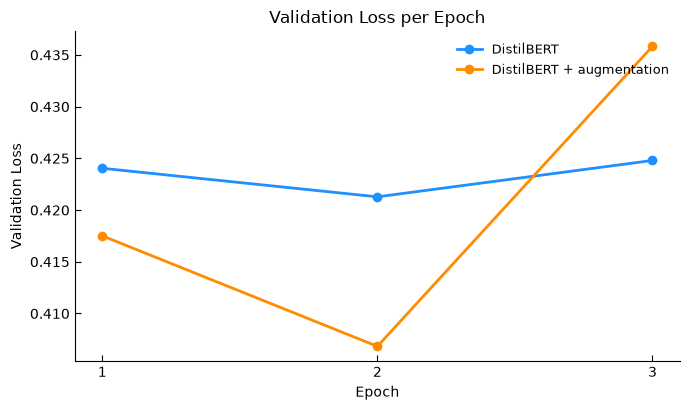

In [9]:
curve_orig = pd.read_csv(f"{OUT}/training_curve.csv")
MODELS = ["DistilBERT", "DistilBERT + augmentation"]
colours = [COLORS[1], COLORS[2]]

fig, ax = plt.subplots(figsize=(7, 4.2))

for colour, name, curve_df in zip(colours, MODELS, [curve_orig, curve_aug]):
    ax.plot(curve_df.epoch, curve_df.val_loss, marker="o", lw=2, color=colour, label=name)

ax.set_xticks(range(1, EPOCHS + 1))
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation Loss")
ax.set_title("Validation Loss per Epoch")
style(ax)
ax.legend(frameon=False, loc="upper right", fontsize=9)

save_fig("fig_augmentation_validation_loss")
plt.show()
plt.close(fig)

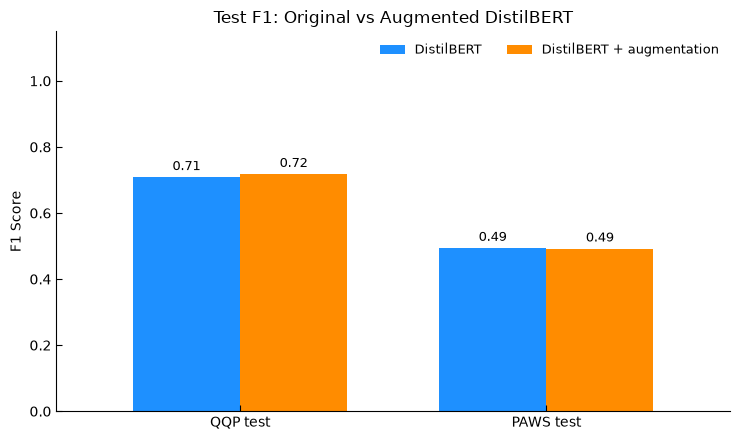

In [10]:
f1_table = comparison.pivot(index="dataset", columns="model", values="f1")
f1_table = f1_table.loc[["QQP test", "PAWS test"], MODELS]

fig, ax = plt.subplots(figsize=(7.5, 4.5))
f1_table.plot(kind="bar", ax=ax, rot=0, color=colours, width=0.7)

for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)

ax.set_ylim(0, 1.15)
ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_xlabel("")
ax.set_ylabel("F1 Score")
ax.set_title("Test F1: Original vs Augmented DistilBERT")
style(ax)
ax.legend(frameon=False, title="", loc="upper right", ncol=2, fontsize=9)

save_fig("fig_augmentation_f1")
plt.show()
plt.close(fig)

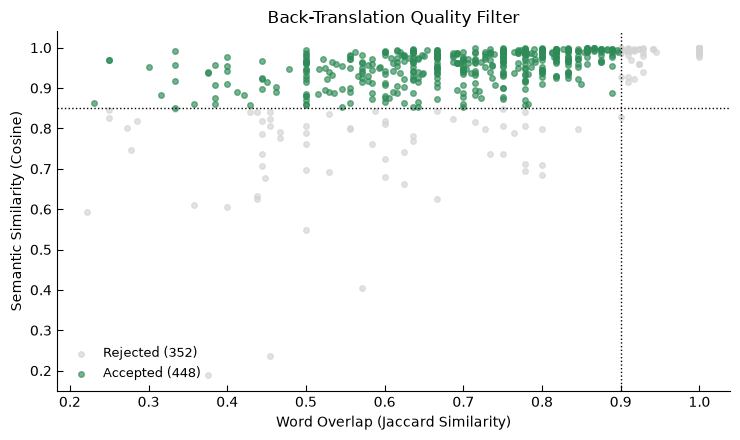

In [11]:
# Separate accepted and rejected paraphrases
accepted = aug[aug["accepted"] == True]
rejected = aug[aug["accepted"] == False]

fig, ax = plt.subplots(figsize=(7.5, 4.5))

ax.scatter(rejected["overlap"], rejected["similarity"], color="lightgrey", s=16, alpha=0.65, label=f"Rejected ({len(rejected)})")

ax.scatter(accepted["overlap"], accepted["similarity"], color=COLORS[0], s=16, alpha=0.65, label=f"Accepted ({len(accepted)})")

ax.axhline(MIN_SIM, color="black", linestyle=":", linewidth=1)
ax.axvline(MAX_OVERLAP, color="black", linestyle=":", linewidth=1)

ax.set_xlabel("Word Overlap (Jaccard Similarity)")
ax.set_ylabel("Semantic Similarity (Cosine)")
ax.set_title("Back-Translation Quality Filter")

style(ax)

ax.legend(loc="lower left", frameon=False, fontsize=9)

save_fig("fig_augmentation_filter")
plt.show()
plt.close(fig)

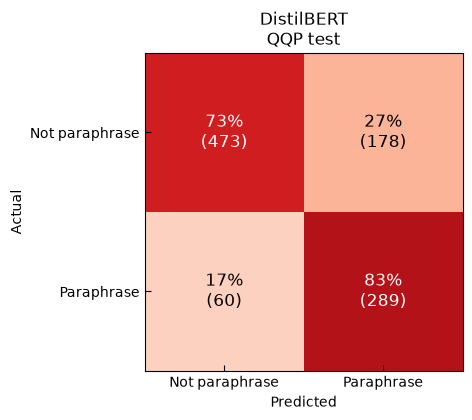

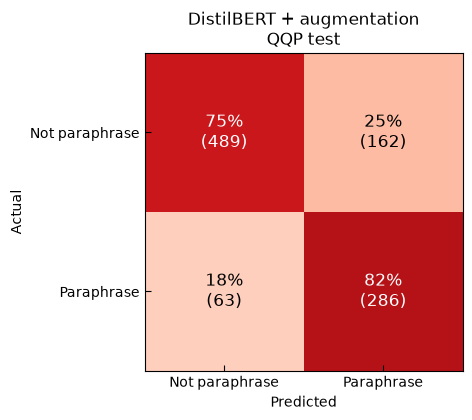

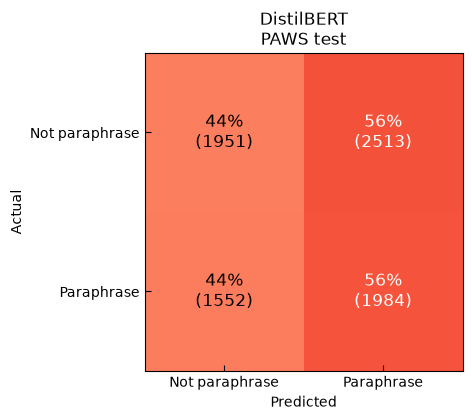

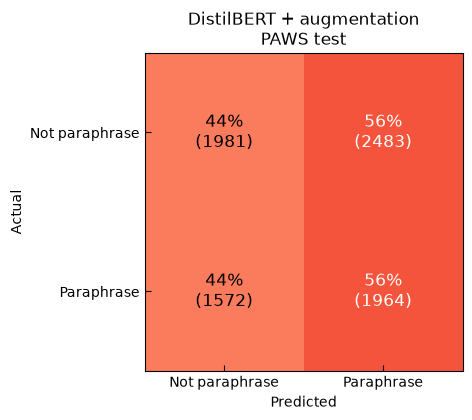

In [12]:
def plot_confusion(row, title, filename):

    # Create the confusion matrix from the evaluation results
    counts = np.array([[row.TN, row.FP], [row.FN, row.TP]])

    # Convert counts to percentages within each actual class
    row_totals = counts.sum(axis=1, keepdims=True)
    percentages = counts / row_totals

    fig, ax = plt.subplots(figsize=(5, 4.3))

    ax.imshow(percentages, cmap="Reds", vmin=0, vmax=1)

    for i in range(2):
        for j in range(2):

            percentage = percentages[i, j]
            count = counts[i, j]

            # Use white text on darker cells
            text_colour = "white" if percentage > 0.5 else "black"

            ax.text(j, i, f"{percentage:.0%}\n({count})", ha="center", va="center", fontsize=12, color=text_colour)

    class_names = ["Not paraphrase", "Paraphrase"]

    ax.set_xticks([0, 1], class_names)
    ax.set_yticks([0, 1], class_names)

    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(title)

    ax.tick_params(axis="both", direction="in", length=4)

    save_fig(filename)
    plt.show()
    plt.close(fig)


# Datasets to evaluate
DATASETS = ["QQP test", "PAWS test"]

models = [("DistilBERT", "fig_confusion_original"), ("DistilBERT + augmentation", "fig_confusion_augmented")]

# Generate a confusion matrix for each model on each dataset
for DATASET in DATASETS:

    for model, filename in models:

        selected = comparison[(comparison["model"] == model) & (comparison["dataset"] == DATASET)]

        row = selected.iloc[0]

        dataset_name = DATASET.split()[0].lower()
        output_name = f"{filename}_{dataset_name}"

        plot_confusion(row, f"{model}\n{DATASET}", output_name)